# OpenAI, Google, and Qwen model on nine classes from Fitz17k 


In [7]:
import os
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "fitz_metadata").is_dir())  # repo root

# API keys come from the gitignored .env file at the repo root (KEY=value lines, no quotes needed).
# Shell variables already set take precedence; values are never printed.
for line in (REPO / ".env").read_text().splitlines() if (REPO / ".env").exists() else []:
    line = line.strip()
    if line and not line.startswith("#") and "=" in line:
        k, v = line.split("=", 1)
        os.environ.setdefault(k.strip(), v.strip().strip('"').strip("'"))

#API_MODELS = ["gpt-image-2.5-sunburst", "nano-banana-2.1"]   # best current OpenAI and Google models
API_MODELS = ["gpt-image-2.5-sunburst"]   # best current OpenAI and Google models
# other rows available in Z.MODELS: "gpt-image-2.5-flare", "gpt-image-2", "gpt-image-1.5", "nano-banana-pro", "nano-banana-2"
LOCAL_MODELS = ["qwen-image-2.1"]          # add "flux-3-klein", "sdxl" for more open-model rows (cached, free)
LABELS = None                              # None = all nine classes; e.g. ["psoriasis"] for a quick test
N_T2I_PER_PROMPT = 2                       # per prompt template (paper, clinical)
N_EDIT = 4                                 # reference-image edits per class (one per real reference)
LOCAL_RESOLUTION = 768
MAX_WORKERS = 4                            # parallel API calls per model

IMAGES_DIR = "/root/data/fitzpatrick17k/finalfitz17k"   # mirrored at /workspace/data/fitzpatrick17k/finalfitz17k
METADATA_CSV = REPO / "fitz_metadata/fitzpatrick17k_10label_clean_training.csv"
OUT_DIR = "/workspace/synderm/zero_shot_screen"


In [8]:
import sys, time
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
os.environ.setdefault("HF_HOME", "/workspace/.cache/huggingface")
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
sys.path.insert(0, str(REPO / "paper_experiments/2026"))
import zero_shot_screen as Z

labels = LABELS or Z.CLASSES
cache = Z.Cache(Path(OUT_DIR))
print("keys:", {p: Z.has_key(p) for p in ("openai", "google")})
pd.DataFrame([vars(Z.MODELS[m]) for m in API_MODELS + LOCAL_MODELS]).set_index("name")


keys: {'openai': True, 'google': True}


,provider,model_id,price_per_image,quality,notes
name,,,,,
gpt-image-2.5-sunburst,openai,gpt-image-2.5-sunburst,0.07,medium,
qwen-image-2.1,local,qwen-image-2.1,0.00,NaN,"768 px, 40 steps, 5090"


## 1. Real images

Four real examples per class for the grid and two more as edit references, drawn with a fixed seed
from the clean training split (never from the held-out set). The loader raises if a file is missing.

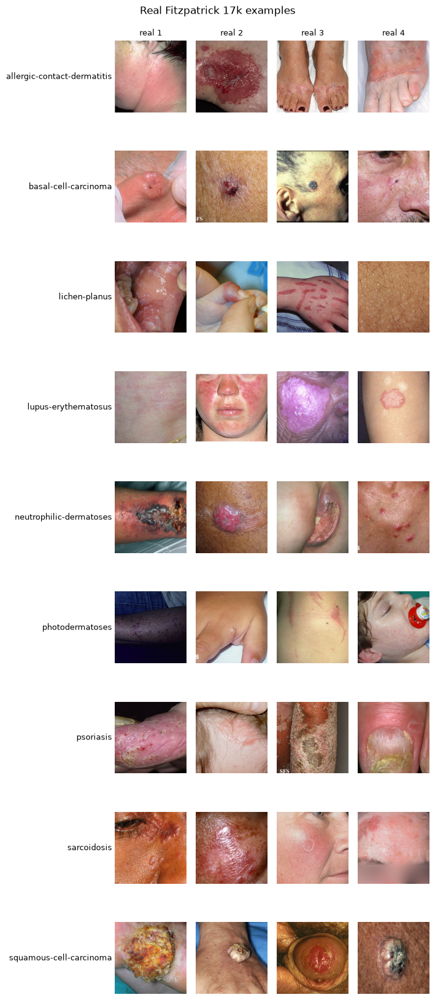

In [9]:
real = Z.real_examples(Path(IMAGES_DIR), Path(METADATA_CSV), labels=labels, n_show=4, n_ref=N_EDIT, seed=0)
rows = [[Z._thumb(p, 192) for p in real[l]["show"]] for l in labels]
Z.show_grid(rows, labels, [f"real {i+1}" for i in range(4)], size=1.8, suptitle="Real Fitzpatrick 17k examples");


## 2. Prompts

Text-to-image uses the paper's prompt and the package's clinical template; edits use the package's
edit instruction (same disease, different patient, same skin tone).

In [10]:
for key, tmpl in Z.PROMPT_TEMPLATES.items():
    print(f"{key:9s}", Z.P.caption("psoriasis", tmpl))
print(f"{'edit':9s}", Z.P.caption("psoriasis", Z.EDIT_TEMPLATE))


paper     An image of psoriasis, a skin disease
clinical  A clinical dermatology photograph of psoriasis, a skin disease, showing the affected skin in close-up under even lighting, sharp focus, no text or annotations.
edit      A clinical photograph of the same skin disease, psoriasis, on a different patient who has the same skin tone, at a different body site, keeping the characteristic appearance of the lesions. No text, watermarks or annotations.


## 3. API models

Each model runs its jobs through a small thread pool. Refusals (`moderation_blocked` on OpenAI, an
empty image on Google) are recorded and not retried; transient errors are retried on the next run.

In [11]:
for name in API_MODELS:
    spec = Z.MODELS[name]
    jobs = Z.make_jobs(name, real, N_T2I_PER_PROMPT, N_EDIT, labels) # 2 t2i prompts * 9 labels * 2 generations = 36 + 18 edit = 54 generations
    t = time.time()
    Z.run_api_model(spec, jobs, cache, max_workers=MAX_WORKERS)
    print(f"  {name}: {time.time() - t:.0f} s\n")


gpt-image-2.5-sunburst: 0 to run, 72 cached
  gpt-image-2.5-sunburst: 0 s



## 4. Open models, zero-shot

Qwen-Image-2.1 without a LoRA, 768 px, one job at a time on the GPU (about 8.5 s per image plus a
few minutes to load from the network disk). Edits use the backend's reference-image mode.

In [30]:
for name in LOCAL_MODELS:
    spec = Z.MODELS[name]
    jobs = Z.make_jobs(name, real, N_T2I_PER_PROMPT, N_EDIT, labels)
    t = time.time()
    Z.run_local_model(spec, jobs, cache, resolution=LOCAL_RESOLUTION)
    print(f"  {name}: {time.time() - t:.0f} s\n")


KeyboardInterrupt: 

## 5. Grids, one per class

Top row: four real examples, then the four real images used as edit references. Each model row:
two text-to-image samples with the paper prompt, two with the clinical prompt, and the four edits
aligned under their references. Grey tiles name the reason an image is missing.

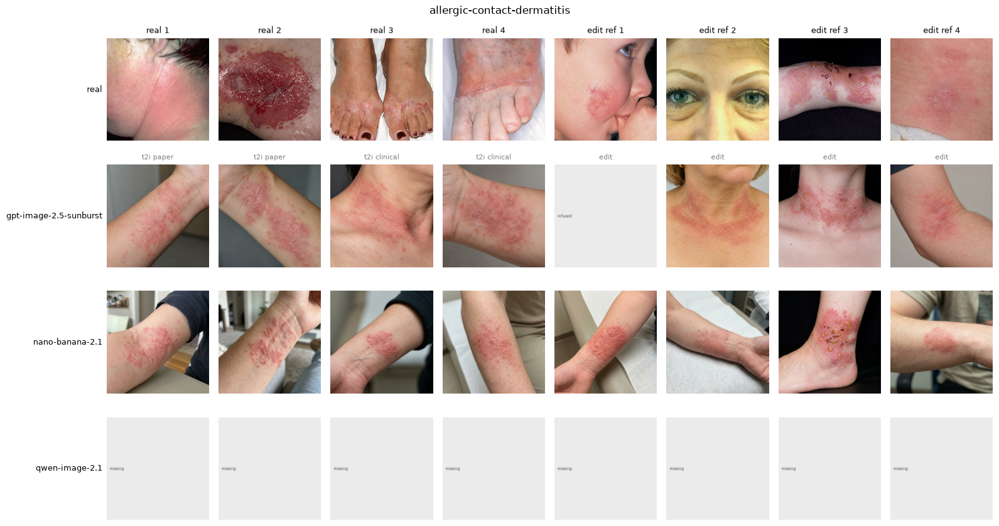

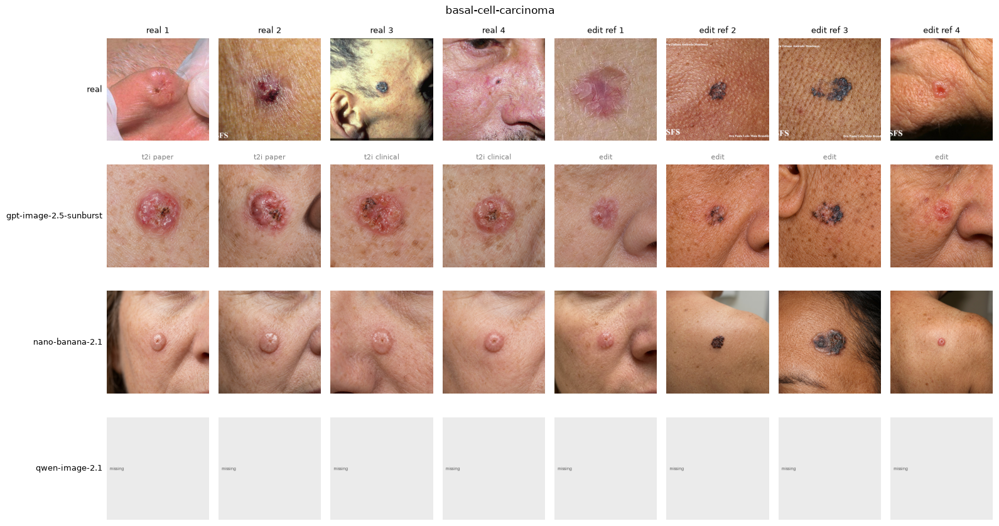

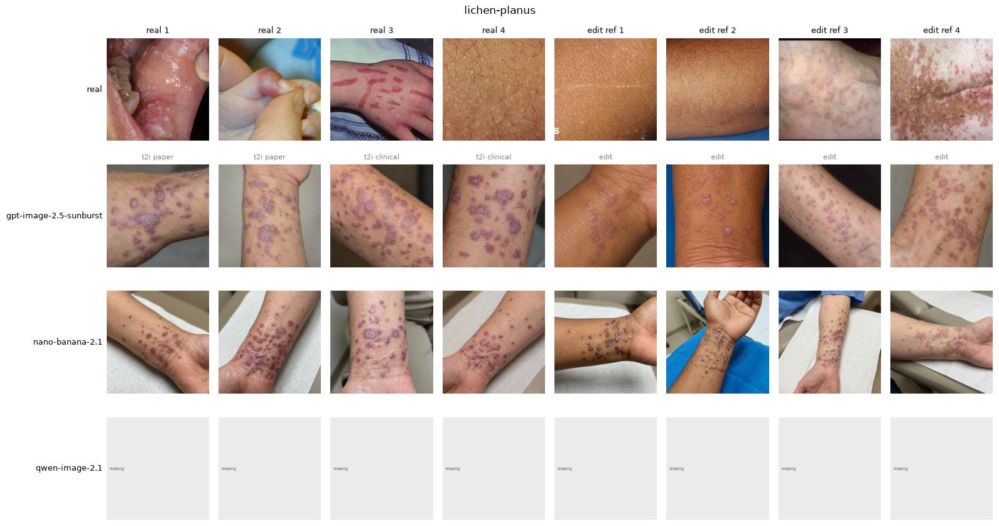

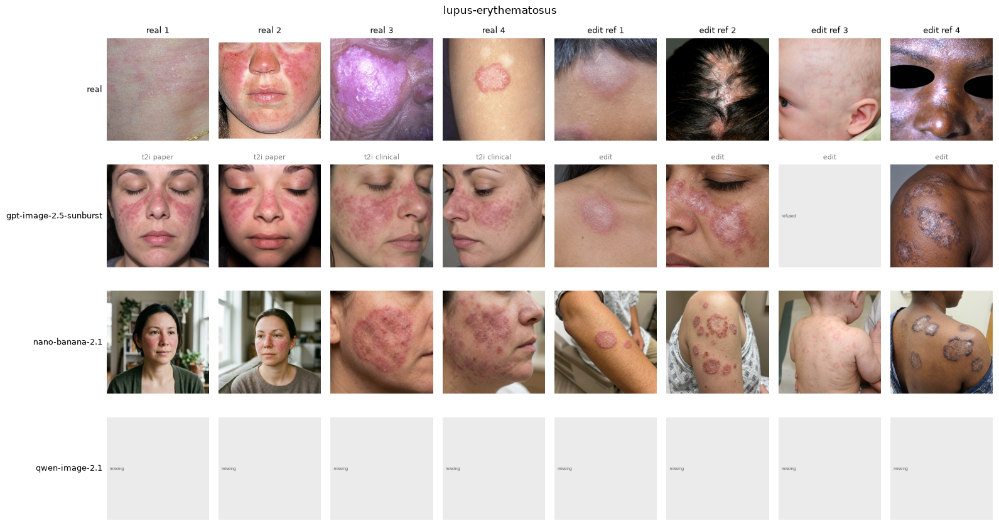

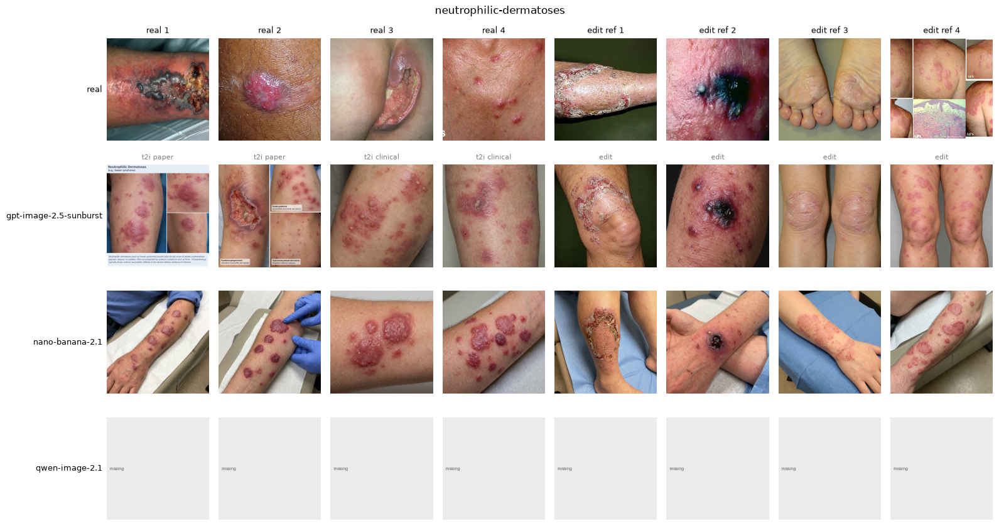

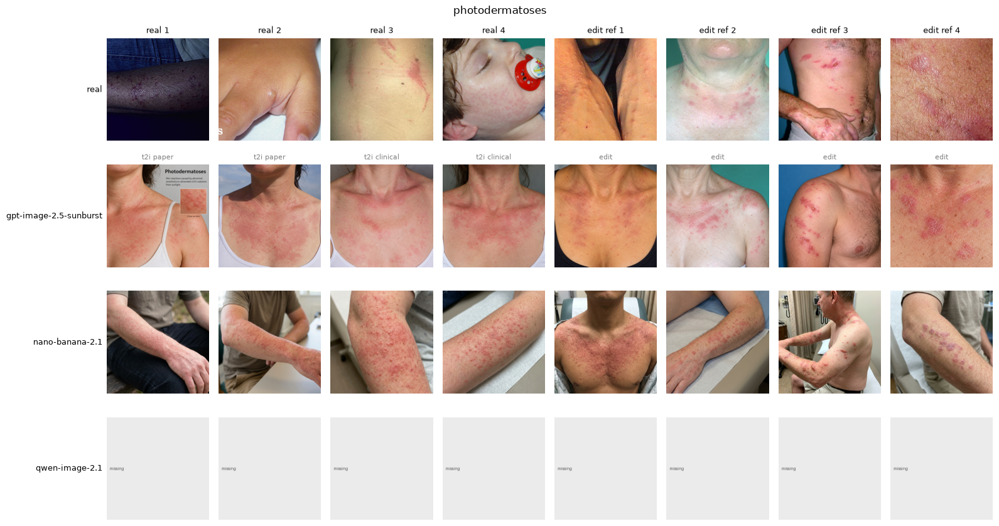

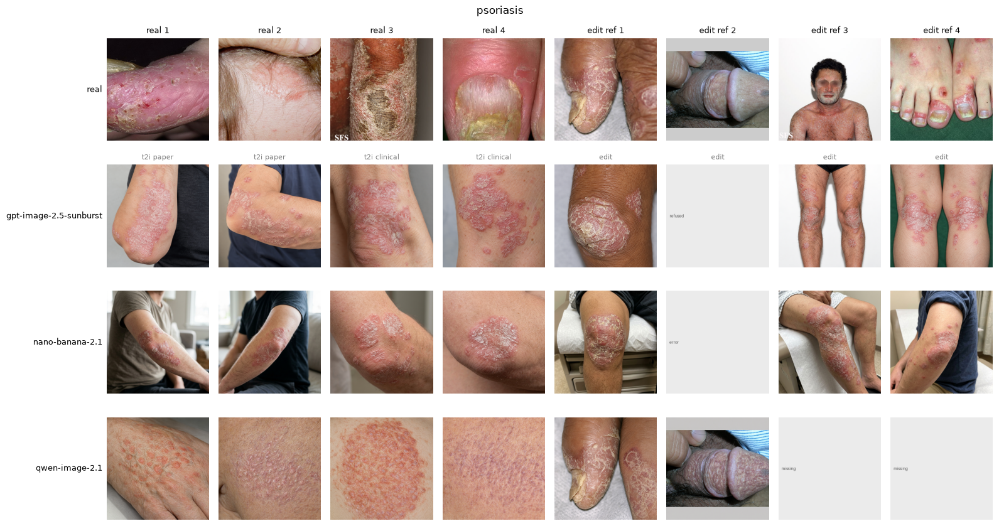

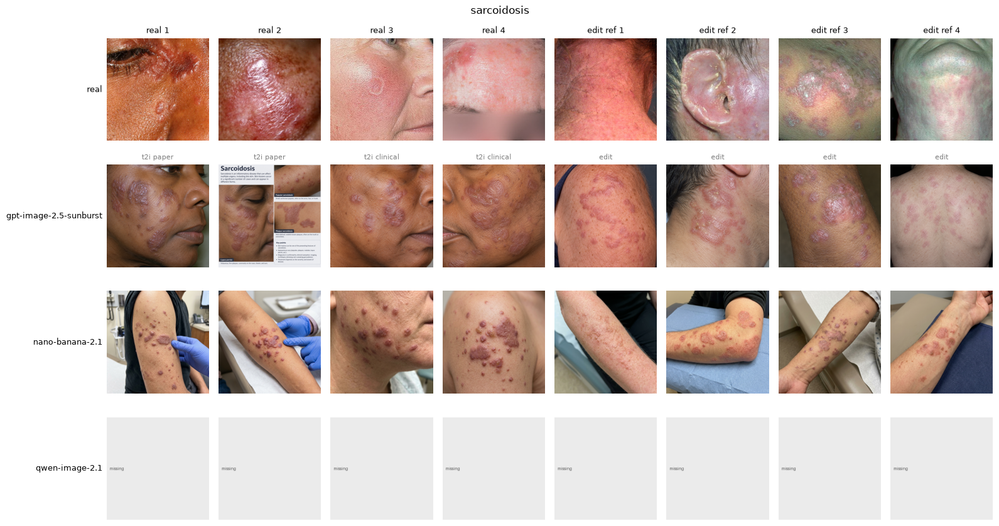

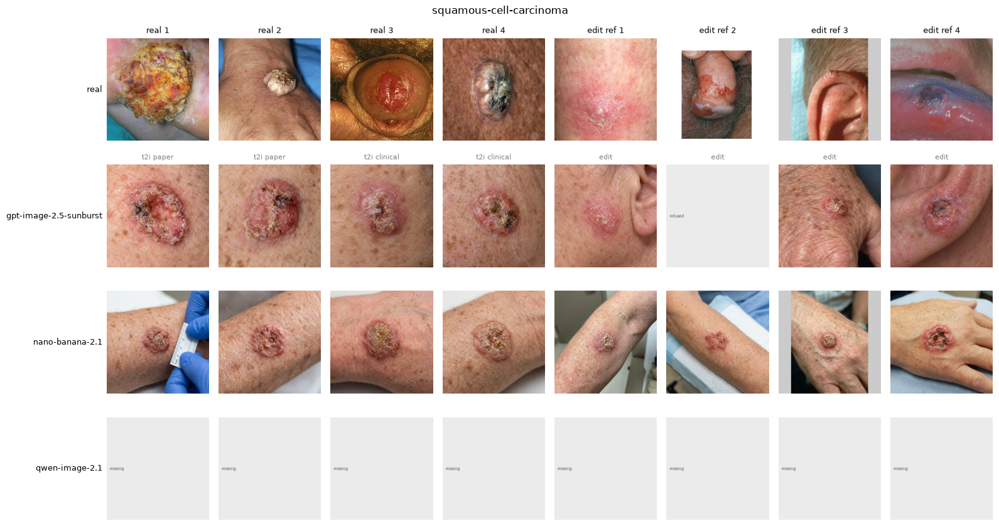

In [13]:
models = API_MODELS + LOCAL_MODELS
for lab in labels:
    rows, row_titles, col_titles, col_titles_models = Z.class_grid(lab, models, real, cache, thumb=256, n_t2i_per_prompt=N_T2I_PER_PROMPT, n_edit=N_EDIT)
    Z.show_grid(rows, row_titles, col_titles, col_titles_models, size=2.0, suptitle=lab,
                save=Path(OUT_DIR) / "grids" / f"{lab}.png")
    plt.show()


## 6. Within-reference variability: 10 edits of the same real image

The pilot (plan Step 1) generates 10 edits per real image from the same reference and the same
prompt, so the only variation comes from the model's sampling. Before running it, check what
those 10 look like: for 3 references per class, ask each model for 10 edits and show the reference
on the left with its 10 edits to the right. Near-copies mean the augmentation would act like
upweighting one image; different body sites, framing and lesion layout mean real augmentation.

Cost: 2 API models x 9 classes x 3 references x 10 = 540 edits, about $14 at measured prices.
Add `"qwen-image-2.1"` to `VARIABILITY_MODELS` to include untuned Qwen (about an hour of GPU).

In [12]:
VARIABILITY_MODELS = API_MODELS          # e.g. API_MODELS + ["qwen-image-2.1"]
N_VAR_REFS = 3                            # references per class (taken from the edit references above)
N_VAR_EDITS = 10                          # edits per reference, as in the pilot

var_jobs = {}
for name in VARIABILITY_MODELS:
    jobs = []
    for lab in labels:
        for r, ref_path in enumerate(real[lab]["ref"][:N_VAR_REFS]):
            for i in range(N_VAR_EDITS):
                jobs.append(Z.Job(name, lab, "edit", f"var{r}", i, Z.P.caption(lab, Z.EDIT_TEMPLATE), str(ref_path)))
    var_jobs[name] = jobs
    spec = Z.MODELS[name]
    t = time.time()
    if spec.provider == "local":
        Z.run_local_model(spec, jobs, cache, resolution=LOCAL_RESOLUTION)
    else:
        Z.run_api_model(spec, jobs, cache, max_workers=MAX_WORKERS)
    print(f"  {name}: {len(jobs)} jobs, {time.time() - t:.0f} s\n")


gpt-image-2.5-sunburst: 0 to run, 270 cached
  gpt-image-2.5-sunburst: 270 jobs, 2 s



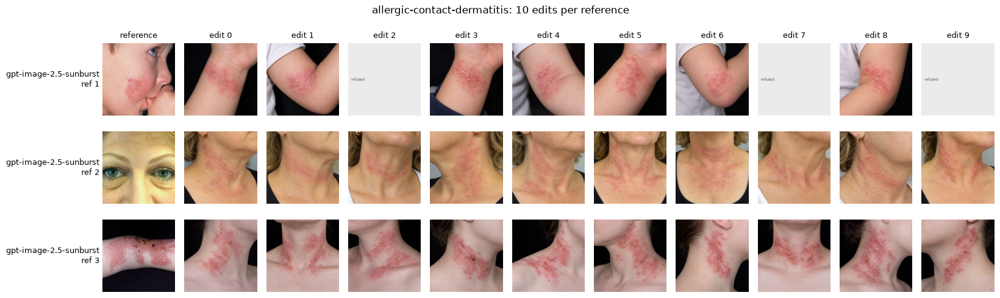

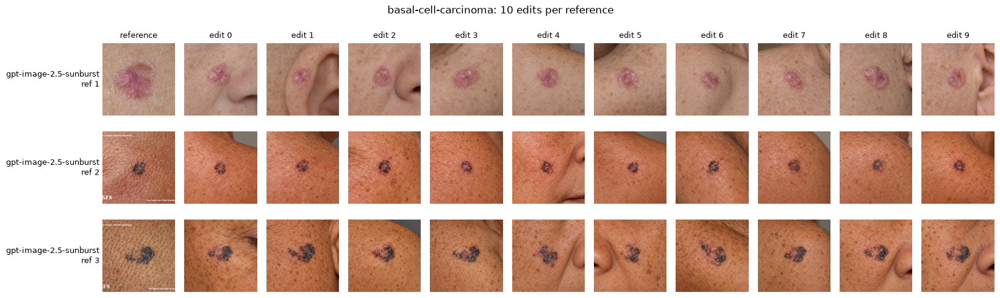

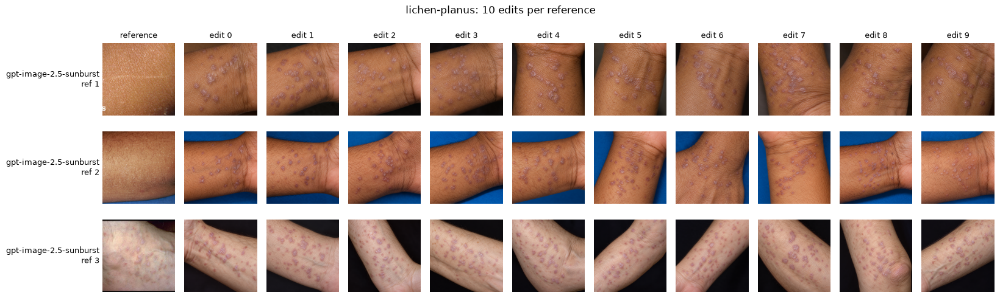

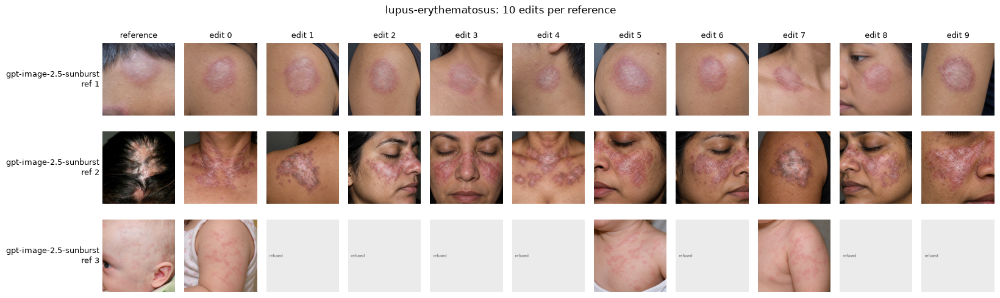

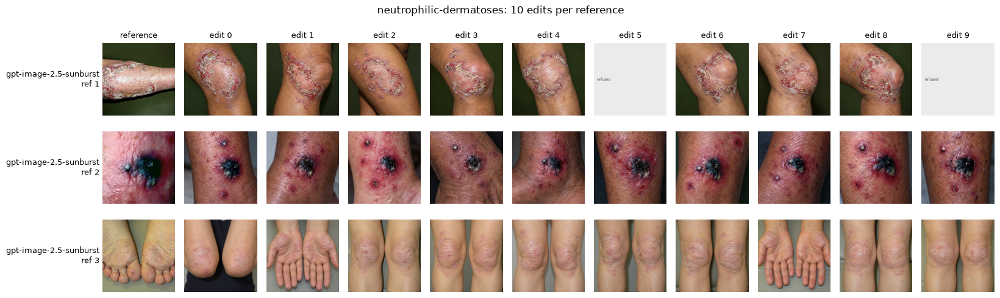

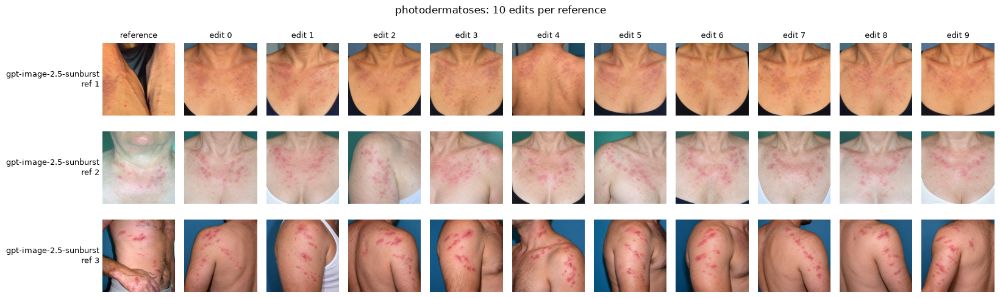

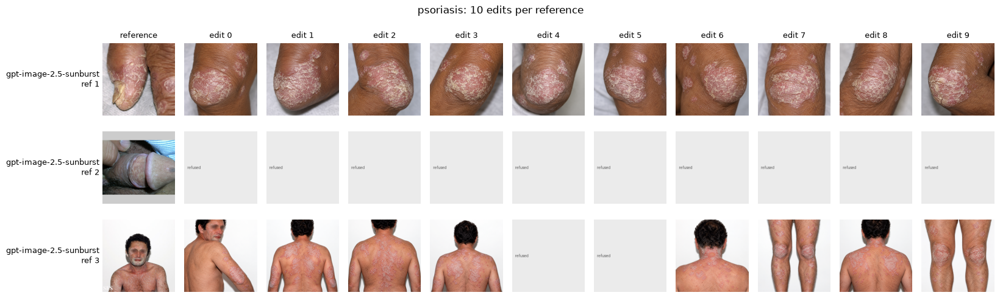

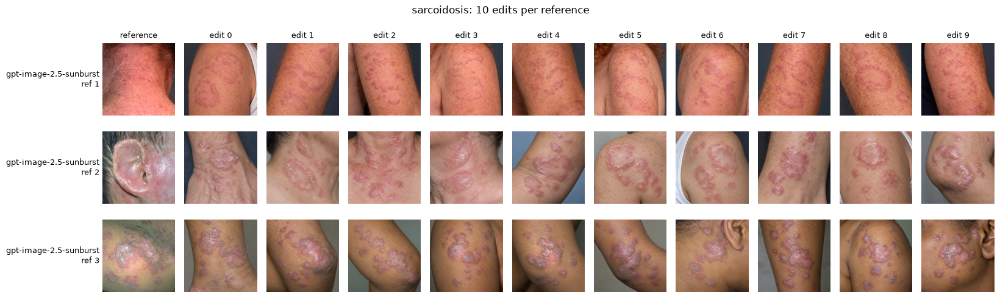

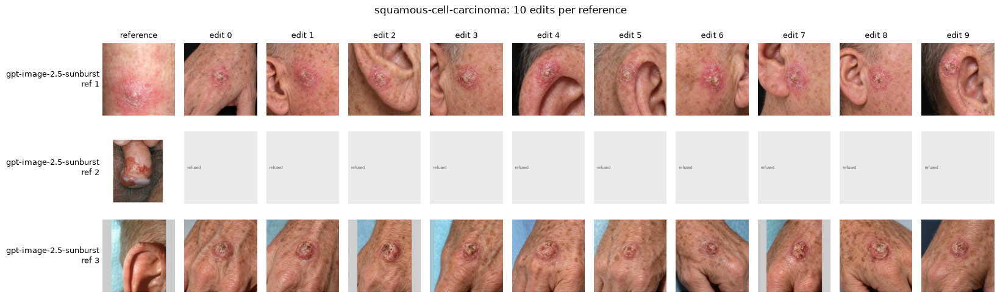

In [10]:
for lab in labels:
    rows, row_titles = [], []
    for name in VARIABILITY_MODELS:
        for r, ref_path in enumerate(real[lab]["ref"][:N_VAR_REFS]):
            row = [Z._thumb(ref_path, 192)]
            for i in range(N_VAR_EDITS):
                job = Z.Job(name, lab, "edit", f"var{r}", i, "")
                st = cache.status(job)
                row.append(Z._thumb(cache.png(job), 192) if st == "ok" else Z._placeholder(st or "missing", 192))
            rows.append(row); row_titles.append(f"{name}\nref {r + 1}")
    Z.show_grid(rows, row_titles, ["reference"] + [f"edit {i}" for i in range(N_VAR_EDITS)], size=1.5,
                suptitle=f"{lab}: {N_VAR_EDITS} edits per reference", save=Path(OUT_DIR) / "variability" / f"{lab}.png")
    plt.show()


What to look for: do the 10 edits of one reference differ in body site, framing and lesion
layout, or are they near-copies of each other and of the reference? Compare against the
text-to-image collapse in the grids above. This decides whether 10 edits per real is a sensible
pilot design or whether the prompt needs per-edit variation (site, skin type, framing).

## 6b. Variability from 10 different prompts

Same 3 references per class as section 6, but each of the 10 edits uses a different prompt. The
shared frame fixes what the pilot must keep (same disease, same lesion appearance, same skin tone
as the reference, no text); the varying clause changes body site, lesion extent, framing, angle,
lighting and patient age. The same 10 prompts are used for every class and reference, so the
variation is orthogonal to the label. Compare these grids with section 6 to see how much
diversity the prompts buy over repeated sampling. Same cost as section 6.

In [ ]:
EDIT_FRAME = ("A clinical photograph of the same skin disease, {condition}, keeping the characteristic appearance "
              "of the lesions and the same skin tone as the reference, on a different patient. "
              "No text, watermarks or annotations. {variation}")
EDIT_VARIATIONS = [
    "Close-up of a single lesion on the forearm, exam-room lighting.",
    "Several lesions across the upper back, photographed from about one metre.",
    "Lesions on the cheek and jawline of an older adult, soft daylight from a window.",
    "Lesions on the lower leg and shin, straight-on view, camera flash.",
    "Lesions on the back of the hand and fingers, close-up, slightly oblique angle.",
    "Widespread involvement of the chest and abdomen of a young adult, mid-range view.",
    "Lesions on the neck and behind the ear, close-up, overhead clinic lighting.",
    "Lesions on the thigh, photographed on an exam table with a paper sheet in the background.",
    "Lesions on the scalp margin and forehead, close-up, hair partly visible.",
    "Lesions on the foot and ankle, mid-range view, natural outdoor light.",
]
assert len(EDIT_VARIATIONS) == N_VAR_EDITS

varp_jobs = {}
for name in VARIABILITY_MODELS:
    jobs = []
    for lab in labels:
        condition = Z.P.label_words(lab)
        for r, ref_path in enumerate(real[lab]["ref"][:N_VAR_REFS]):
            for i, variation in enumerate(EDIT_VARIATIONS):
                prompt = EDIT_FRAME.format(condition=condition, variation=variation)
                jobs.append(Z.Job(name, lab, "edit", f"varp{r}", i, prompt, str(ref_path)))
    varp_jobs[name] = jobs
    spec = Z.MODELS[name]
    t = time.time()
    if spec.provider == "local":
        Z.run_local_model(spec, jobs, cache, resolution=LOCAL_RESOLUTION)
    else:
        Z.run_api_model(spec, jobs, cache, max_workers=MAX_WORKERS)
    print(f"  {name}: {len(jobs)} jobs, {time.time() - t:.0f} s\n")


gpt-image-2.5-sunburst: 270 to run, 0 cached
  [1/270] allergic-contact-dermatitis edit refused Error code: 400 - Your request was rejected by the safety system. If you believe this is an error, contact us at help.op
  [2/270] allergic-contact-dermatitis edit refused Error code: 400 - Your request was rejected by the safety system. If you believe this is an error, contact us at help.op
  [6/270] allergic-contact-dermatitis edit refused Error code: 400 - Your request was rejected by the safety system. If you believe this is an error, contact us at help.op
  [7/270] allergic-contact-dermatitis edit refused Error code: 400 - Your request was rejected by the safety system. If you believe this is an error, contact us at help.op
  [10/270] allergic-contact-dermatitis edit ok 
  [16/270] allergic-contact-dermatitis edit refused Error code: 400 - Your request was rejected by the safety system. If you believe this is an error, contact us at help.op
  [20/270] allergic-contact-dermatitis edit ok

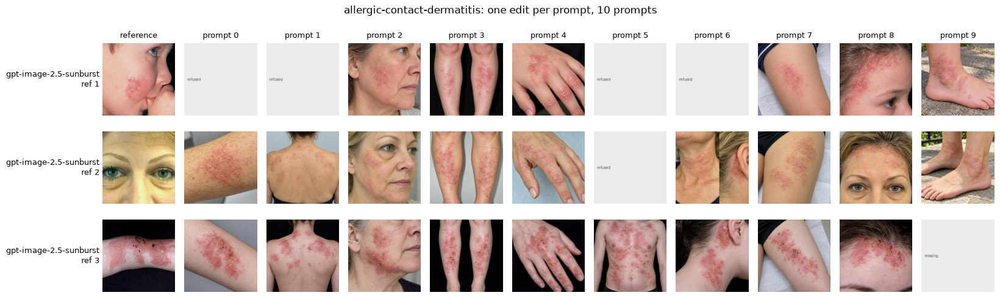

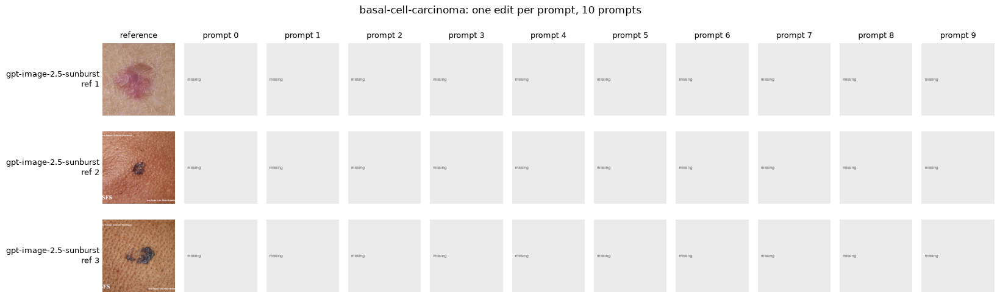

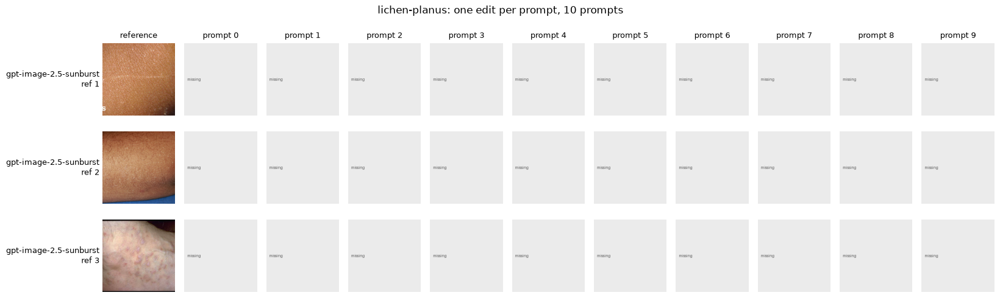

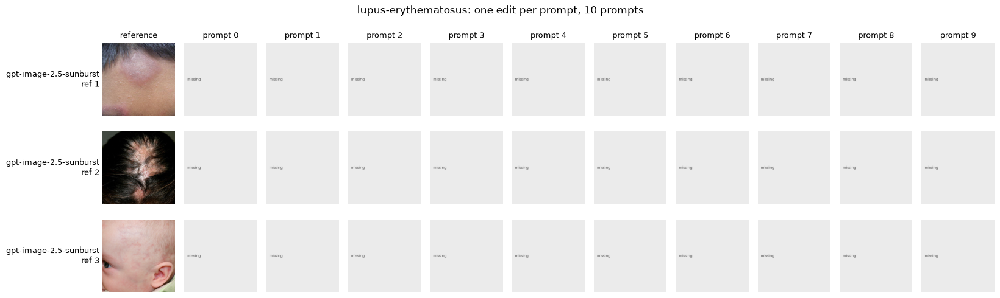

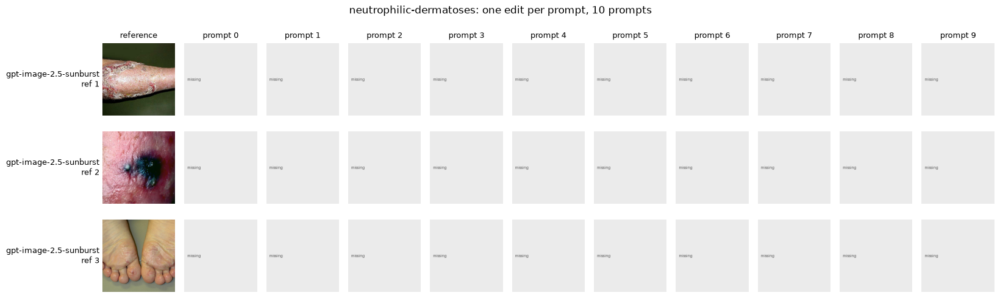

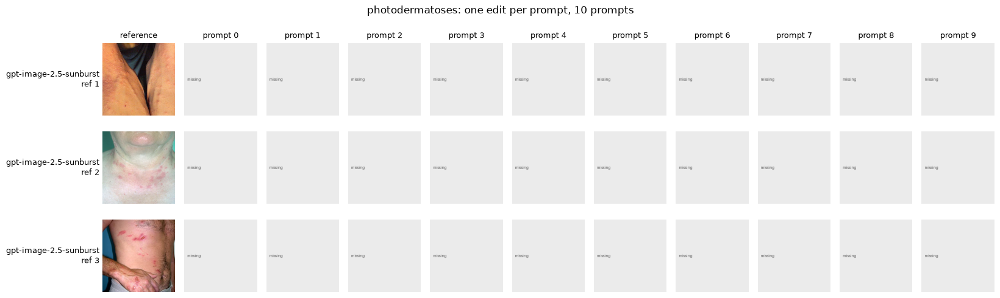

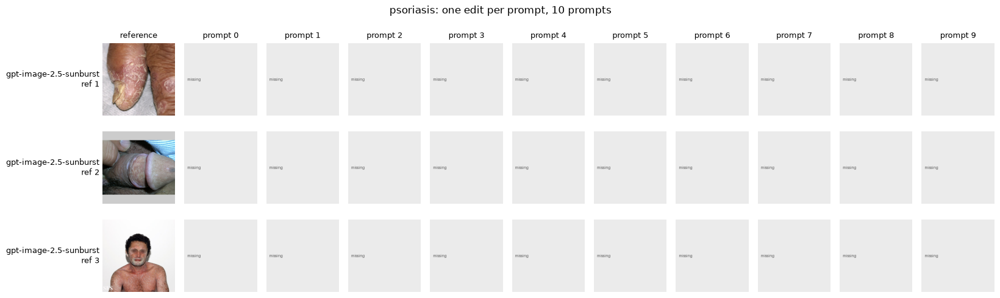

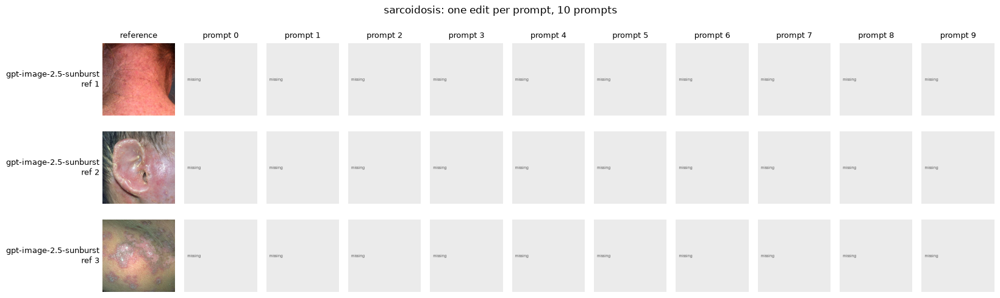

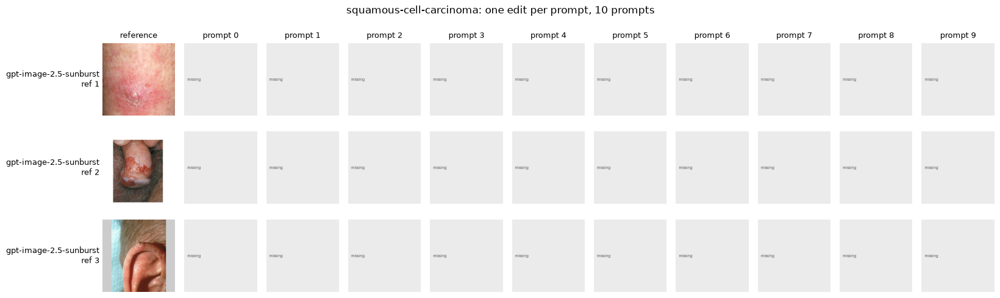

In [13]:
for lab in labels:
    rows, row_titles = [], []
    for name in VARIABILITY_MODELS:
        for r, ref_path in enumerate(real[lab]["ref"][:N_VAR_REFS]):
            row = [Z._thumb(ref_path, 192)]
            for i in range(N_VAR_EDITS):
                job = Z.Job(name, lab, "edit", f"varp{r}", i, "")
                st = cache.status(job)
                row.append(Z._thumb(cache.png(job), 192) if st == "ok" else Z._placeholder(st or "missing", 192))
            rows.append(row); row_titles.append(f"{name}\nref {r + 1}")
    Z.show_grid(rows, row_titles, ["reference"] + [f"prompt {i}" for i in range(N_VAR_EDITS)], size=1.5,
                suptitle=f"{lab}: one edit per prompt, 10 prompts", save=Path(OUT_DIR) / "variability_prompts" / f"{lab}.png")
    plt.show()


Side by side with section 6: if the prompt grids spread across body sites and framings while the
repeated-sampling grids stay near the reference, the pilot should use the 10-prompt scheme (slot k
uses prompt k, same list for every class). Also check that the varied prompts did not change the
disease appearance; a prompt that moves the lesion to a site where the model draws something else
is worse than a near-copy.